# Procesamiento batch de Online Retail con Apache Spark

Notebook organizado por etapas para cargar, limpiar y analizar el conjunto de datos Online Retail.

In [3]:
import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType, TimestampType

# Configurar Java si está instalado en esta ruta
java_home = r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot"
if Path(java_home).exists():
    os.environ["JAVA_HOME"] = java_home
    os.environ["PATH"] = str(Path(java_home) / "bin") + os.pathsep + os.environ.get("PATH", "")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
print("Entorno preparado.")
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

Entorno preparado.


In [4]:
# Buscar Online Retail.xlsx en la carpeta data del proyecto
rutas_excel = [
    Path.cwd() / "data" / "Online Retail.xlsx",
    Path.cwd().parent / "data" / "Online Retail.xlsx"
]
ruta_excel = next((ruta for ruta in rutas_excel if ruta.exists()), None)

if ruta_excel is None:
    raise FileNotFoundError("No se encontró Online Retail.xlsx. Comprueba que esté en la carpeta data del proyecto.")

ventas_pd = pd.read_excel(ruta_excel, engine="openpyxl")
print("Archivo cargado:", ruta_excel)
print("Dimensiones iniciales:", ventas_pd.shape)
display(ventas_pd.head())

Archivo cargado: c:\Users\Rober y Tatiana\Desktop\ROBER\Ingenieria industrial\Ingenieria industrial\6 Semestre\Big Data\Tarea3-Procesamiento de datos con apache spark\procesamiento_batch_unad\data\Online Retail.xlsx
Dimensiones iniciales: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. Inspección y limpieza de los datos

In [5]:
print("Valores faltantes por columna:")
display(ventas_pd.isnull().sum().to_frame("Valores faltantes"))
print("Registros duplicados:", ventas_pd.duplicated().sum())

ventas_pd["InvoiceNo"] = ventas_pd["InvoiceNo"].astype("string").str.strip()
ventas_pd["StockCode"] = ventas_pd["StockCode"].astype("string").str.strip()
ventas_pd["Country"] = ventas_pd["Country"].astype("string").str.strip()
ventas_pd["Description"] = ventas_pd["Description"].fillna("Sin descripción").astype(str)
ventas_pd["Quantity"] = pd.to_numeric(ventas_pd["Quantity"], errors="coerce")
ventas_pd["UnitPrice"] = pd.to_numeric(ventas_pd["UnitPrice"], errors="coerce")
ventas_pd["InvoiceDate"] = pd.to_datetime(ventas_pd["InvoiceDate"], errors="coerce")

ventas_pd = ventas_pd.dropna(subset=["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice", "Country"]).copy()
ventas_pd = ventas_pd[(ventas_pd["Quantity"] > 0) & (ventas_pd["UnitPrice"] > 0)].copy()
ventas_pd["Quantity"] = ventas_pd["Quantity"].astype("int32")
ventas_pd["UnitPrice"] = ventas_pd["UnitPrice"].astype("float64")
ventas_pd["Revenue"] = ventas_pd["Quantity"] * ventas_pd["UnitPrice"]
print("Dimensiones después de limpiar:", ventas_pd.shape)
display(ventas_pd.head())

Valores faltantes por columna:


,Valores faltantes
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Registros duplicados: 5268
Dimensiones después de limpiar: (530104, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 2. Crear la sesión de Apache Spark y el DataFrame

In [6]:
spark = (
    SparkSession.builder
    .appName("Analisis de ventas Online Retail")
    .master("local[2]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Versión de Spark:", spark.version)

Versión de Spark: 3.5.1


In [7]:
# ============================================================
# CREAR DATAFRAME SPARK - ONLINE RETAIL - UNAD
# Compatible con el esquema definido para Spark 3.5.1
# ============================================================

import pandas as pd
from datetime import datetime
from pyspark.sql.types import (
    StructType, StructField, StringType,
    IntegerType, DoubleType, TimestampType
)

# 1. Seleccionar y copiar las columnas
columnas = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country", "Revenue"
]

datos = ventas_pd[columnas].copy()

# 2. Limpiar y convertir los tipos de datos
for columna in ["InvoiceNo", "StockCode", "Description", "CustomerID", "Country"]:
    datos[columna] = datos[columna].map(
        lambda valor: None if pd.isna(valor) else str(valor)
    )

datos["InvoiceDate"] = pd.to_datetime(
    datos["InvoiceDate"], errors="coerce"
)
datos["Quantity"] = pd.to_numeric(datos["Quantity"], errors="coerce")
datos["UnitPrice"] = pd.to_numeric(datos["UnitPrice"], errors="coerce")
datos["Revenue"] = pd.to_numeric(datos["Revenue"], errors="coerce")

# 3. Eliminar registros con campos esenciales inválidos
datos = datos.dropna(
    subset=["InvoiceDate", "Quantity", "UnitPrice", "Revenue"]
).copy()

# 4. Definir el esquema de Spark
esquema = StructType([
    StructField("InvoiceNo", StringType(), True),
    StructField("StockCode", StringType(), True),
    StructField("Description", StringType(), True),
    StructField("Quantity", IntegerType(), True),
    StructField("InvoiceDate", TimestampType(), True),
    StructField("UnitPrice", DoubleType(), True),
    StructField("CustomerID", StringType(), True),
    StructField("Country", StringType(), True),
    StructField("Revenue", DoubleType(), True)
])

# 5. Construir filas con tipos nativos de Python
filas = []

for fila in datos.itertuples(index=False, name=None):
    fecha_original = fila[4]

    # Convertir explícitamente la fecha a datetime.datetime de Python
    if isinstance(fecha_original, pd.Timestamp):
        fecha = fecha_original.to_pydatetime()
    else:
        fecha = pd.Timestamp(fecha_original).to_pydatetime()

    fecha = datetime(
        fecha.year, fecha.month, fecha.day,
        fecha.hour, fecha.minute, fecha.second,
        fecha.microsecond
    )

    filas.append((
        fila[0],
        fila[1],
        fila[2],
        int(fila[3]),
        fecha,
        float(fila[5]),
        fila[6],
        fila[7],
        float(fila[8])
    ))

# 6. Crear el DataFrame de Spark
ventas_spark = spark.createDataFrame(filas, schema=esquema)

# 7. Verificar el resultado
print("DataFrame de Spark creado correctamente.")
print("Registros en Spark:", ventas_spark.count())
print("\nEsquema:")
ventas_spark.printSchema()
print("\nPrimeros cinco registros:")
ventas_spark.show(5, truncate=False)

DataFrame de Spark creado correctamente.
Registros en Spark: 530104

Esquema:
root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- CustomerID: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Revenue: double (nullable = true)


Primeros cinco registros:
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+------------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |Revenue           |
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+------------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |2010-12-01 08:26:00|2.55

## 3. Resumen general de las ventas

In [8]:
ventas_spark.select("Quantity", "UnitPrice", "Revenue").summary().show()
print("Facturas diferentes:", ventas_spark.select("InvoiceNo").distinct().count())
print("Países diferentes:", ventas_spark.select("Country").distinct().count())
ventas_spark.agg(F.sum("Quantity").alias("Total_unidades")).show()
ventas_spark.agg(F.round(F.sum("Revenue"), 2).alias("Ingresos_totales")).show()

+-------+------------------+------------------+------------------+
|summary|          Quantity|         UnitPrice|           Revenue|
+-------+------------------+------------------+------------------+
|  count|            530104|            530104|            530104|
|   mean|10.542037034242338|3.9076252471184887|20.121871451640274|
| stddev| 155.5241235106358| 35.91568110425544|270.35674321840594|
|    min|                 1|             0.001|             0.001|
|    25%|                 1|              1.25|              3.75|
|    50%|                 3|              2.08|               9.9|
|    75%|                10|              4.13|17.700000000000003|
|    max|             80995|          13541.33|          168469.6|
+-------+------------------+------------------+------------------+

Facturas diferentes: 19960
Países diferentes: 38
+--------------+
|Total_unidades|
+--------------+
|       5588376|
+--------------+

+----------------+
|Ingresos_totales|
+----------------+
|  

## 4. Ingresos por país

In [9]:
ingresos_pais = (ventas_spark.groupBy("Country")
    .agg(F.round(F.sum("Revenue"), 2).alias("Ingresos"))
    .orderBy(F.desc("Ingresos")))
ingresos_pais.show(15, truncate=False)

+--------------+----------+
|Country       |Ingresos  |
+--------------+----------+
|United Kingdom|9025222.08|
|Netherlands   |285446.34 |
|EIRE          |283453.96 |
|Germany       |228867.14 |
|France        |209715.11 |
|Australia     |138521.31 |
|Spain         |61577.11  |
|Switzerland   |57089.9   |
|Belgium       |41196.34  |
|Sweden        |38378.33  |
|Japan         |37416.37  |
|Norway        |36165.44  |
|Portugal      |33747.1   |
|Finland       |22546.08  |
|Singapore     |21279.29  |
+--------------+----------+
only showing top 15 rows



## 5. Productos más vendidos por unidades

In [10]:
productos_vendidos = (ventas_spark.groupBy("StockCode", "Description")
    .agg(F.sum("Quantity").alias("Unidades_vendidas"))
    .orderBy(F.desc("Unidades_vendidas")))
productos_vendidos.show(10, truncate=False)

+---------+----------------------------------+-----------------+
|StockCode|Description                       |Unidades_vendidas|
+---------+----------------------------------+-----------------+
|23843    |PAPER CRAFT , LITTLE BIRDIE       |80995            |
|23166    |MEDIUM CERAMIC TOP STORAGE JAR    |78033            |
|84077    |WORLD WAR 2 GLIDERS ASSTD DESIGNS |55047            |
|85099B   |JUMBO BAG RED RETROSPOT           |48474            |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|37599            |
|22197    |POPCORN HOLDER                    |36761            |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |36461            |
|21212    |PACK OF 72 RETROSPOT CAKE CASES   |36419            |
|23084    |RABBIT NIGHT LIGHT                |30788            |
|22492    |MINI PAINT SET VINTAGE            |26633            |
+---------+----------------------------------+-----------------+
only showing top 10 rows



## 6. RDD y reduceByKey

In [11]:
rdd_ingresos = ventas_spark.select("Country", "Revenue").rdd.map(lambda fila: (fila["Country"], fila["Revenue"]))
ingresos_rdd = rdd_ingresos.reduceByKey(lambda a, b: a + b)
resultado_rdd = ingresos_rdd.sortBy(lambda elemento: elemento[1], ascending=False).take(10)
for pais, ingresos in resultado_rdd:
    print(f"{pais}: {ingresos:,.2f}")

United Kingdom: 9,025,222.08
Netherlands: 285,446.34
EIRE: 283,453.96
Germany: 228,867.14
France: 209,715.11
Australia: 138,521.31
Spain: 61,577.11
Switzerland: 57,089.90
Belgium: 41,196.34
Sweden: 38,378.33


## 7. Gráficas

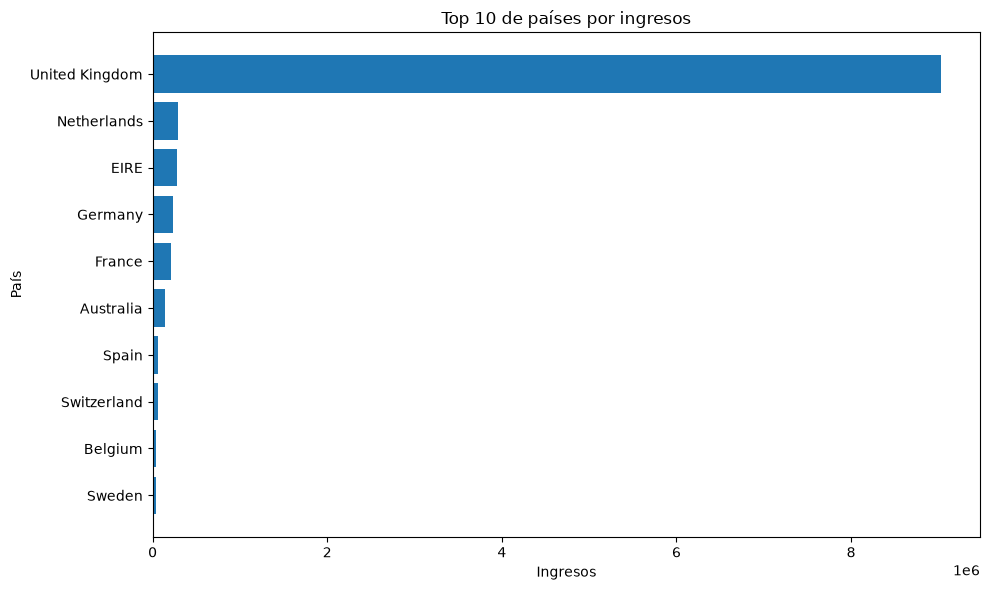

In [12]:
datos_grafica = ingresos_pais.limit(10).toPandas().sort_values("Ingresos", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(datos_grafica["Country"], datos_grafica["Ingresos"])
plt.title("Top 10 de países por ingresos")
plt.xlabel("Ingresos")
plt.ylabel("País")
plt.tight_layout()
plt.show()

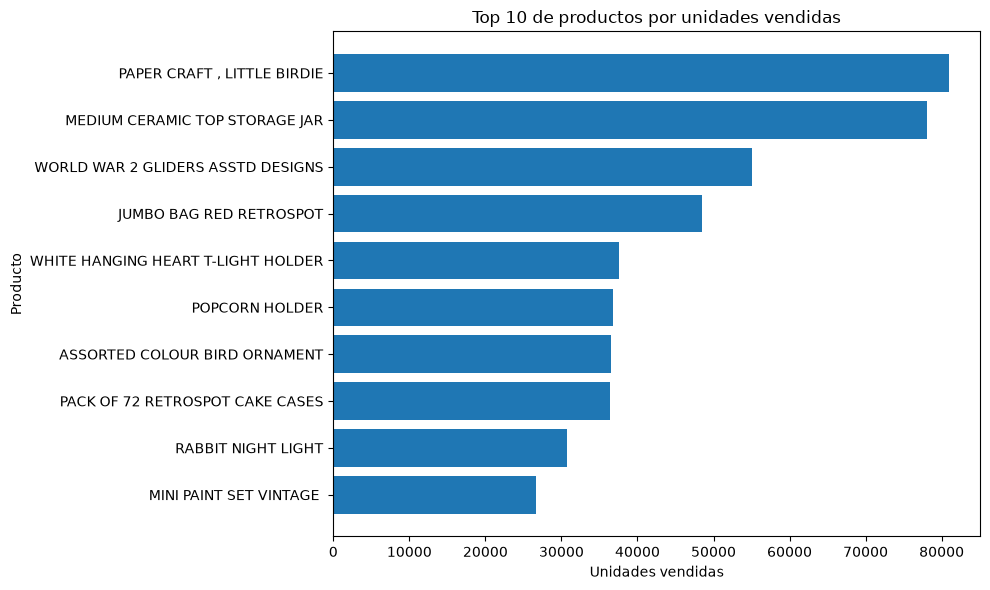

In [13]:
datos_productos = productos_vendidos.limit(10).toPandas().sort_values("Unidades_vendidas", ascending=True)
etiquetas = datos_productos["Description"].str.slice(0, 35)
plt.figure(figsize=(10, 6))
plt.barh(etiquetas, datos_productos["Unidades_vendidas"])
plt.title("Top 10 de productos por unidades vendidas")
plt.xlabel("Unidades vendidas")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

## 8. Cerrar Spark

Ejecuta esta celda solamente después de terminar todos los análisis.

In [14]:
spark.stop()
print("Sesión de Spark cerrada correctamente.")

Sesión de Spark cerrada correctamente.


In [2]:
%pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     --------------- ------------------------ 30.7/80.3 kB 1.3 MB/s eta 0:00:01
     ------------------------ ------------- 51.2/80.3 kB 871.5 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 636.6 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     ------------------- ------------------- 71.7/139.8 kB 2.0 MB/s eta 0:00:01
     -------------------------------------- 139.8/139.8 kB 1.7 MB/s eta 0:00:00
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/9.3 MB 1.7 MB/s eta 0:00:06
    --------------------------------------- 0.1/9.3 MB 1.4 MB/s eta 0:00:07
    ----------------------------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
import os
import subprocess

print("Python:", sys.executable)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))

resultado = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

print(resultado.stderr or resultado.stdout)

Python: c:\Users\Rober y Tatiana\AppData\Local\Programs\Python\Python311\python.exe
JAVA_HOME: None
openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)

